# Benchmark Structures

Which brain structures are suitable as a benchmark for judging whether an image-enhancement
pipeline improves 64mT scans? A good benchmark shows the gap between 64mT and 3T clearly, and in
the same way for every subject, so that an improvement would be visible.

## Why WMH-SynthSeg

- **Dice (Chapter 05)**: WMH-SynthSeg agrees better with 3T on FLAIR and T1w, and equally on T2w.
- **Volume (Chapter 06)**: SynthSeg systematically underestimates deep and lower-brain structures
  on 64mT, with segmentation failures (zero volume).

From here on only WMH-SynthSeg is used: 64mT compared with 3T lowres, repeated scans averaged per
subject (n = 11), the same 17 regions as Chapters 05 and 06.

In [1]:
import sys

import matplotlib.pyplot as plt
import nibabel as nib
import numpy as np
import pandas as pd
import torch

from common import OLD_OUT, P, LOGS, fs

sys.path.insert(0, str(P['wmh_code'] / 'WMHSynthSeg'))
from utils import MRIread, align_volume_to_ref, myzoom_torch

DICE, REG, VOL = OLD_OUT / 'dice', OLD_OUT / 'reg', OLD_OUT / 'volume'
MODS = ['T2w', 'T1w', 'FLAIR']
# region -> merged label id in the Chapter 05 label maps
LABEL = {'WM': 2, 'Cortex': 3, 'Lateral-Ventricle': 4, 'Cerebellum-WM': 7, 'Cerebellum-Cortex': 8,
         'Thalamus': 10, 'Caudate': 11, 'Putamen': 12, 'Pallidum': 13, '3rd-Ventricle': 14,
         '4th-Ventricle': 15, 'Brainstem': 16, 'Hippocampus': 17, 'Amygdala': 18, 'CSF': 24,
         'Accumbens': 26, 'VentralDC': 28}

pairs = pd.read_csv(REG / 'pairs_lowres.csv', keep_default_na=False).set_index('pair_id')
dice = pd.read_csv(DICE / 'dice_WMH_SynthSeg_lowres.csv')
dice = dice[dice.region.isin(LABEL)]
# one value per subject: average repeated sessions / runs first
subj = dice.groupby(['subject', 'modality', 'region'], as_index=False)[['dice_np', 'n_3T']].mean()
bias = pd.read_csv(VOL / 'bias_long.csv').query("tool == 'WMH_SynthSeg'")    # Chapter 06, per subject

/home/jovyan/conda-envs/lfbook/lib/python3.11/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


## How Dice and volume relate

Registration has been checked (Chapter 04), so the two label maps are aligned. Then:

- **High Dice → small volume difference.** Two maps that overlap well cannot differ much in size.
- **Small volume difference → Dice can still be low.** Two maps can have the same volume and
  still disagree on where the boundary is. This happens most for thin, folded structures.

So volume alone can hide a gap that Dice shows. Dice also depends on the structure itself: its
size, and how much of it lies on a boundary.

The first point sets an upper limit. If the 64mT map is (1 + b) times the 3T map, the overlap is
at most the smaller map, so Dice ≤ 2 · min(1, 1 + b) / (2 + b) (dashed line). Each point below is
one region: median volume bias (Chapter 06) and median Dice of 11 subjects, bars = Q1–Q3.

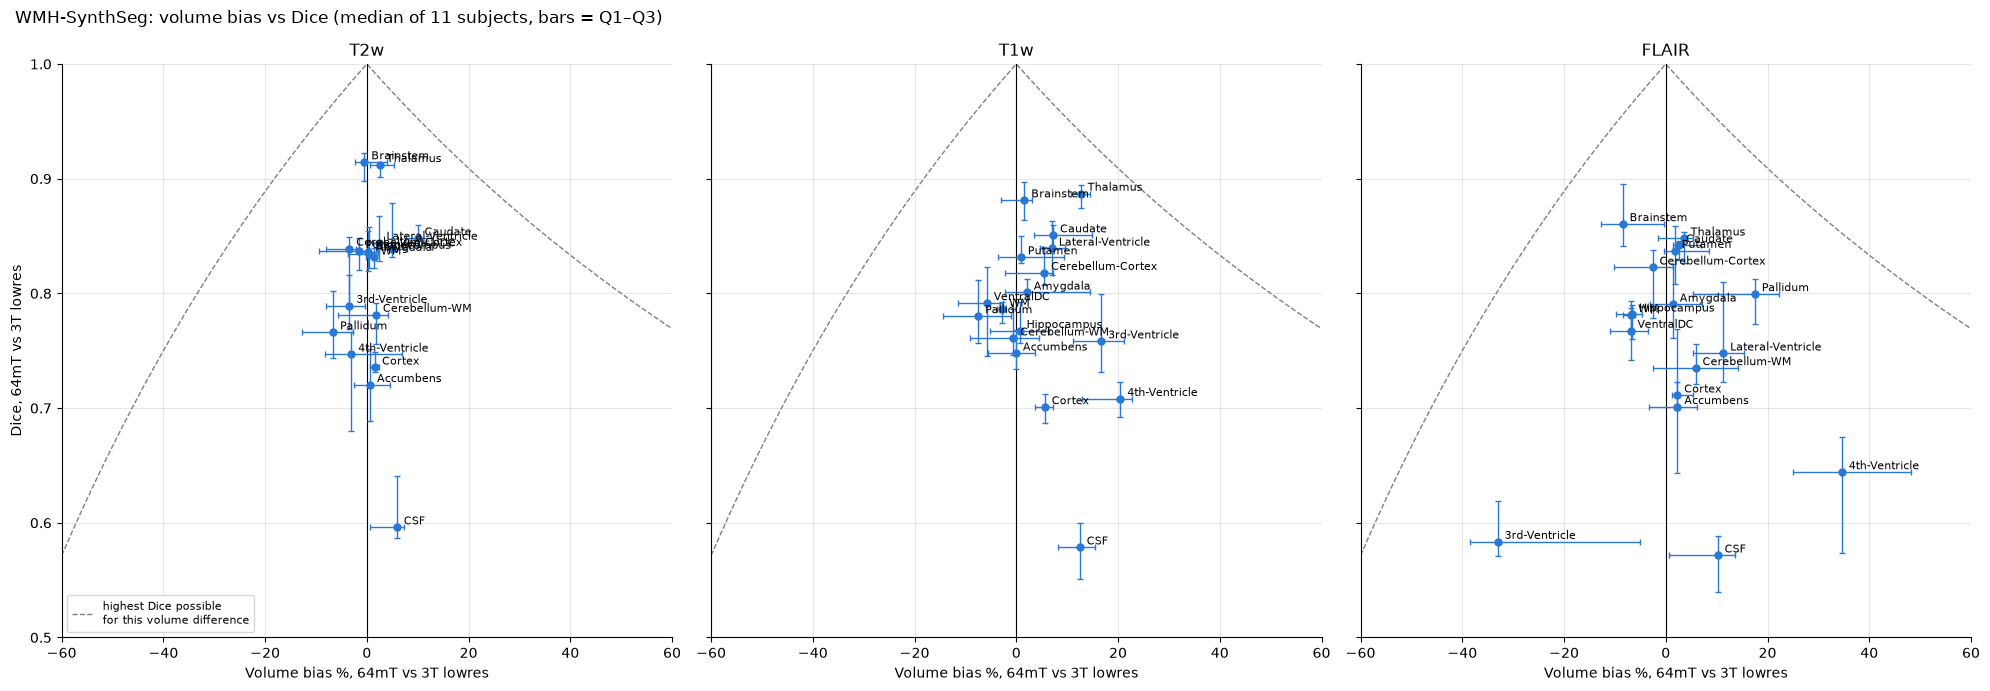

In [2]:
def plot_bias_dice():
    q = [0.25, 0.5, 0.75]
    d = subj[subj.region.isin(LABEL)].groupby(['modality', 'region']).dice_np.quantile(q).unstack()
    b = bias[bias.region.isin(LABEL)].groupby(['modality', 'region']).pct_diff.quantile(q).unstack()
    t = d.join(b, lsuffix='_d', rsuffix='_b').reset_index()
    x = np.linspace(-60, 60, 241)
    bound = 2 * np.minimum(1, 1 + x / 100) / (2 + x / 100)
    fig, axes = plt.subplots(1, 3, figsize=(20, 7), sharex=True, sharey=True)
    for ax, mod in zip(axes, MODS):
        s = t[t.modality == mod]
        ax.plot(x, bound, '--', color='grey', lw=1, label='highest Dice possible\nfor this volume difference')
        ax.axvline(0, color='black', lw=0.8)
        ax.errorbar(s['0.5_b'], s['0.5_d'], xerr=[s['0.5_b'] - s['0.25_b'], s['0.75_b'] - s['0.5_b']],
                    yerr=[s['0.5_d'] - s['0.25_d'], s['0.75_d'] - s['0.5_d']],
                    fmt='o', ms=5, color='#2a78d6', lw=1, capsize=2)
        for _, r in s.iterrows():
            ax.annotate(r.region, (r['0.5_b'], r['0.5_d']), xytext=(5, 2), textcoords='offset points', fontsize=8)
        ax.set(title=mod, xlim=(-60, 60), ylim=(0.5, 1), xlabel='Volume bias %, 64mT vs 3T lowres')
        ax.grid(alpha=0.3)
        ax.spines[['top', 'right']].set_visible(False)
    axes[0].set_ylabel('Dice, 64mT vs 3T lowres')
    axes[0].legend(loc='lower left', fontsize=8)
    fig.suptitle('WMH-SynthSeg: volume bias vs Dice (median of 11 subjects, bars = Q1–Q3)', x=0.01, ha='left')
    plt.tight_layout()
    plt.show()


plot_bias_dice()

Overall the two measures agree: no region with a high Dice has a large volume bias, and the
regions with a large bias have a low Dice. Two exceptions stand out:

- **CSF** has a small bias (+6 to +12 %) but the lowest Dice (about 0.6), far below the line: the
  two maps have nearly the same size but disagree on where the boundary is.
- **3rd and 4th ventricle on FLAIR** have the largest biases, in opposite directions (about −33 %
  and +35 %), and a Dice near 0.6. A global size error would shift both the same way, so this
  points to errors at these structures on FLAIR.

## Structure size and Dice

Each point is one region: median Dice of 11 subjects, bar = Q1–Q3 (spread between subjects);
x = size of the structure on 3T.

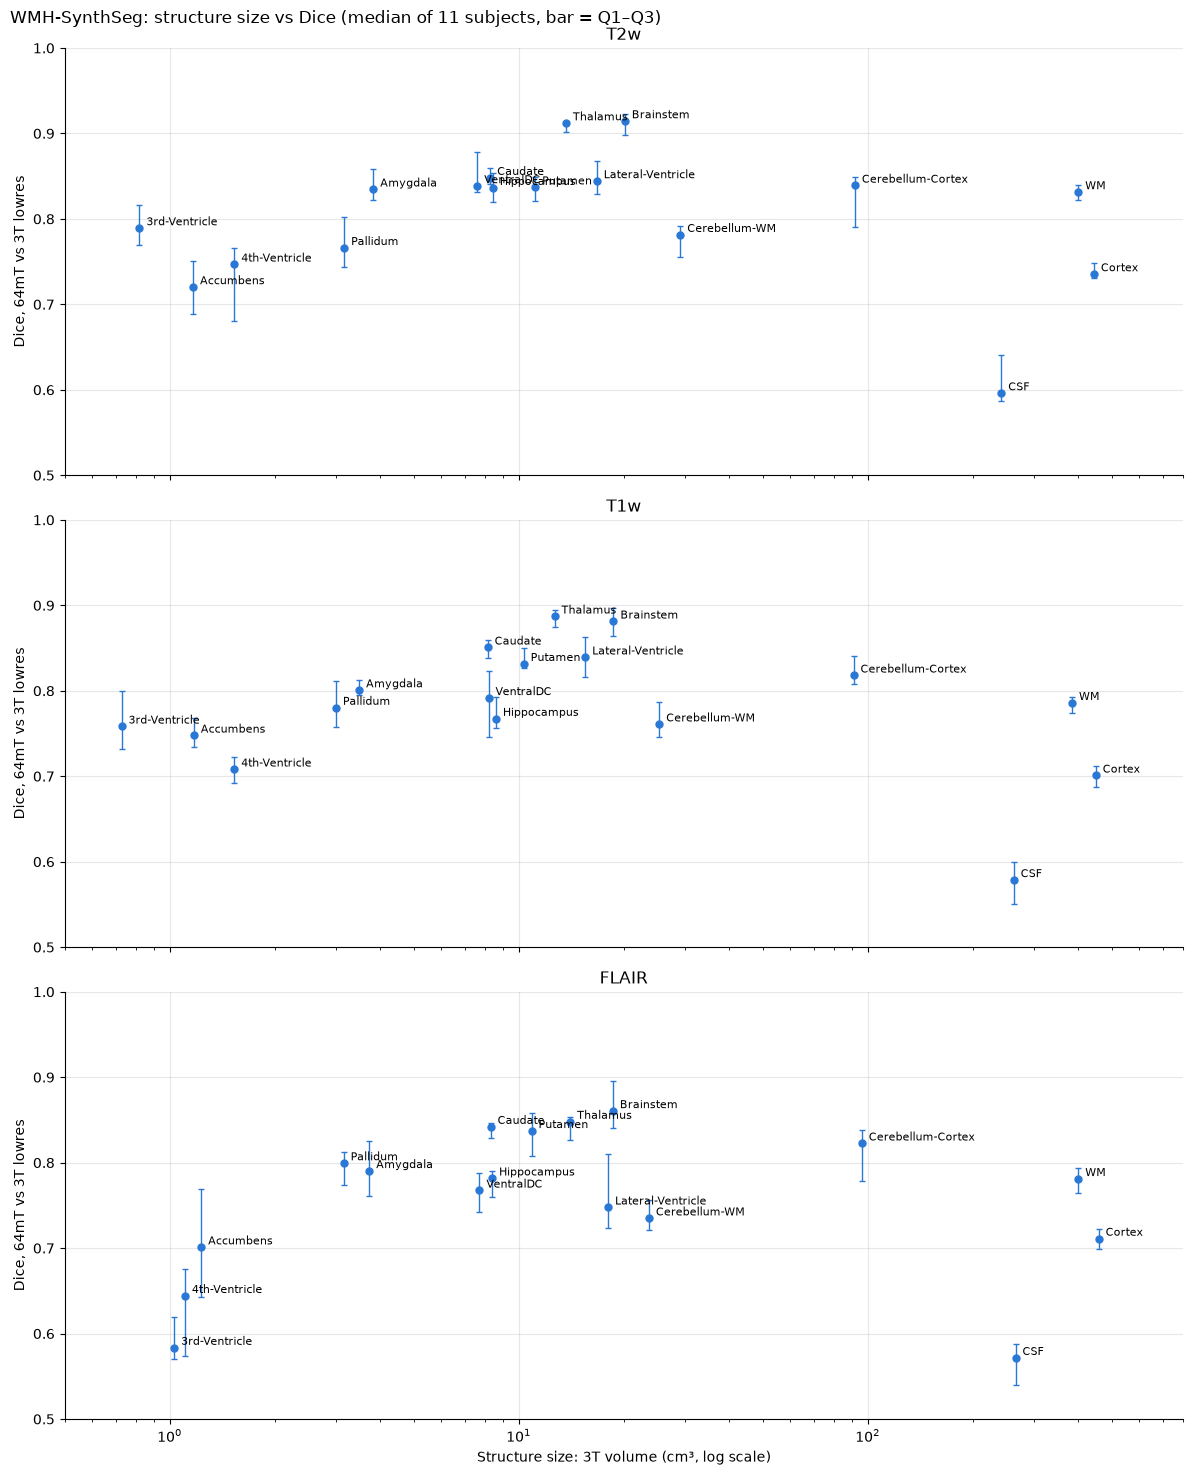

In [3]:
def plot_size_dice():
    g = subj.groupby(['modality', 'region'])
    t = pd.DataFrame(dict(vol=g.n_3T.median() / 1000, q1=g.dice_np.quantile(0.25),
                          dice=g.dice_np.median(), q3=g.dice_np.quantile(0.75))).reset_index()
    fig, axes = plt.subplots(3, 1, figsize=(12, 15), sharex=True)
    for ax, mod in zip(axes, MODS):
        x = t[t.modality == mod]
        ax.errorbar(x.vol, x.dice, yerr=[x.dice - x.q1, x.q3 - x.dice], fmt='o', ms=5,
                    color='#2a78d6', lw=1, capsize=2)
        for _, r in x.iterrows():
            ax.annotate(r.region, (r.vol, r.dice), xytext=(5, 2), textcoords='offset points', fontsize=8)
        ax.set(xscale='log', title=mod, ylabel='Dice, 64mT vs 3T lowres', xlim=(0.5, 800), ylim=(0.5, 1))
        ax.grid(alpha=0.3)
        ax.spines[['top', 'right']].set_visible(False)
    axes[-1].set_xlabel('Structure size: 3T volume (cm³, log scale)')
    fig.suptitle('WMH-SynthSeg: structure size vs Dice (median of 11 subjects, bar = Q1–Q3)', x=0.01, ha='left')
    plt.tight_layout()
    plt.show()


plot_size_dice()

Three groups stand out:

1. **High Dice**: thalamus and brainstem, at the top.
2. **Small structures**: 3rd and 4th ventricle, accumbens, pallidum, on the left; on FLAIR they
   drop lowest and spread most.
3. **Large, low but stable**: cortex and CSF, bottom right, with short bars.

The remaining regions sit in between and are not discussed further.

## The three groups

For each group: Dice as median (IQR) of 11 subjects; volume bias (Chapter 06) as median % [Q1, Q3];
and one subject on T2w, chosen as the pair whose Dice is closest to the group median.

The figure shows four axial slices through the structures. For each slice: the 3T and 64mT
images (top), each with its own label map (bottom; red = 3T, blue = 64mT), and the two label maps
on the 3T image (right; red = 3T only, blue = 64mT only, purple = both). The images are the ones
WMH-SynthSeg segmented (1 mm, Chapter 03); the 64mT image and label map are moved onto the 3T grid
with the Chapter 04 registration, so all five panels show the same slice.

In [4]:
def group_table(regions):
    rows = {}
    for r in regions:
        row = {}
        for mod in MODS:
            d = subj[(subj.region == r) & (subj.modality == mod)].dice_np.quantile([0.25, 0.5, 0.75])
            b = bias[(bias.region == r) & (bias.modality == mod)].pct_diff.quantile([0.25, 0.5, 0.75])
            row[('Dice', mod)] = f'{d[0.5]:.2f} ({d[0.75] - d[0.25]:.2f})'
            row[('Volume bias %', mod)] = f'{b[0.5]:+.0f} [{b[0.25]:+.0f}, {b[0.75]:+.0f}]'
        rows[r] = row
    return pd.DataFrame(rows).T


FIG = DICE / 'work' / 'figures_07'                 # images on the 3T label-map grid, for the figures
RED, BLUE, PURPLE = [0.85, 0.1, 0.1], [0.1, 0.35, 0.9], [0.6, 0.2, 0.75]


def wmh_input(src, seg, dst):
    """Save the image WMH-SynthSeg segmented (as Chapter 03: RAS, divided by its maximum,
    1 mm with myzoom_torch) to dst. It is on the grid of its label map `seg`."""
    if dst.exists():
        return
    image, aff = MRIread(src)
    x = torch.tensor(np.squeeze(image).astype(float))
    x, aff2 = align_volume_to_ref(x, aff, aff_ref=np.eye(4), return_aff=True, n_dims=3)
    x = myzoom_torch(x / torch.max(x), np.sqrt(np.sum(aff2 ** 2, axis=0))[:-1], device='cpu').numpy()
    lab = nib.load(seg)
    assert x.shape == lab.shape, (src, x.shape, lab.shape)
    nib.save(nib.Nifti1Image(x.astype(np.float32), lab.affine), dst)


def case_images(pid):
    """3T image, 64mT image moved onto the 3T grid, and the two Chapter 05 label maps (all on one grid)."""
    r = pairs.loc[pid]
    FIG.mkdir(parents=True, exist_ok=True)
    hf_img, lf_img, moved = (FIG / f'{pid}_{s}.nii.gz' for s in ['3T_1mm', '64mT_1mm', '64mT_on_3T'])
    wmh_input(r['fix_raw'], r['fix_WMH_SynthSeg'], hf_img)
    wmh_input(r['mov_raw'], r['mov_WMH_SynthSeg'], lf_img)
    if not moved.exists():                         # same transform as the 64mT label map (Chapter 05)
        fs(f"mri_vol2vol --mov {lf_img} --targ {r['fix_WMH_SynthSeg']} --lta {REG / 'xfm_lowres'}/{pid}.lta "
           f"--trilin --o {moved} --no-save-reg", log=LOGS / 'figures_07.log', show=False)
    work = DICE / 'work' / 'WMH_SynthSeg_lowres'
    load = lambda f: np.asarray(nib.as_closest_canonical(nib.load(f)).dataobj)
    return [load(f) for f in [hf_img, moved, work / f'{pid}_3T_h.nii.gz', work / f'{pid}_64mT_h.nii.gz']]


def plot_case(title, regions, hf, lf, hf_lab, lf_lab, n_slices=4, per_row=2):
    """Per slice: 2 x 2 grid (3T, 64mT; each with its label map) and the overlap on the right."""
    ids = [LABEL[r] for r in regions]
    A, B = np.isin(hf_lab, ids), np.isin(lf_lab, ids)
    norm = lambda v: (v / np.percentile(v[v > 0], 99)).clip(0, 1)
    hf, lf = norm(hf), norm(lf)
    xs, ys, _ = np.where(hf > 0.05)                                   # whole head
    crop = np.s_[xs.min():xs.max() + 1, ys.min():ys.max() + 1]
    z = np.where((A | B).any(axis=(0, 1)))[0]                         # slices containing the structures
    ks = z[np.arange(1, n_slices + 1) * len(z) // (n_slices + 1)]

    def panel(ax, img, masks, name):
        ax.imshow(np.rot90(img[crop]), cmap='gray', vmin=0, vmax=1)
        over = np.zeros(img.shape + (4,))
        for m, c in masks:
            over[m] = c + [0.55]
        ax.imshow(np.rot90(over[crop]))
        ax.set_title(name, fontsize=8, pad=2)
        ax.axis('off')

    rows = int(np.ceil(n_slices / per_row))
    h, w = xs.max() - xs.min() + 1, ys.max() - ys.min() + 1           # panel aspect after rot90: w / h
    fig = plt.figure(figsize=(per_row * 4 * 2.8 * h / w + 0.4, rows * 2 * 2.8 + 0.8))
    outer = fig.add_gridspec(rows, per_row, left=0.01, right=0.99, bottom=0.01, top=0.94,
                             wspace=0.04, hspace=0.1)
    for n, k in enumerate(ks):
        g = outer[n // per_row, n % per_row].subgridspec(2, 4, wspace=0.03, hspace=0.12)
        a, b = A[:, :, k], B[:, :, k]
        panel(fig.add_subplot(g[0, 0]), hf[:, :, k], [], '3T')
        panel(fig.add_subplot(g[0, 1]), lf[:, :, k], [], '64mT')
        panel(fig.add_subplot(g[1, 0]), hf[:, :, k], [(a, RED)], '3T label')
        panel(fig.add_subplot(g[1, 1]), lf[:, :, k], [(b, BLUE)], '64mT label')
        sd = 2 * (a & b).sum() / max(a.sum() + b.sum(), 1)
        panel(fig.add_subplot(g[:, 2:]), hf[:, :, k], [(a & ~b, RED), (b & ~a, BLUE), (a & b, PURPLE)],
              f'slice {k}: overlap, Dice {sd:.2f}')
    fig.suptitle(title, x=0.01, ha='left', fontsize=10)
    plt.show()


def show_case(regions, mod='T2w', n_slices=4):
    d = dice[(dice.modality == mod) & dice.region.isin(regions)].groupby('pair_id').dice_np.mean()
    pid = (d - d.median()).abs().idxmin()
    title = f"{pid.split('__')[0]}: {', '.join(regions)}   (whole-structure Dice {d[pid]:.2f}; R on right)"
    plot_case(title, regions, *case_images(pid), n_slices=n_slices)

### 1. High Dice: thalamus and brainstem

In [5]:
HIGH = ['Thalamus', 'Brainstem']
group_table(HIGH)

,Dice,Volume bias %,Dice,Volume bias %,Dice,Volume bias %
,T2w,T2w,T1w,T1w,FLAIR,FLAIR
Thalamus,0.91 (0.01),"+3 [+1, +5]",0.89 (0.02),"+13 [+11, +14]",0.85 (0.03),"+4 [-2, +5]"
Brainstem,0.91 (0.02),"-0 [-2, +4]",0.88 (0.03),"+2 [-3, +3]",0.86 (0.05),"-8 [-13, -0]"


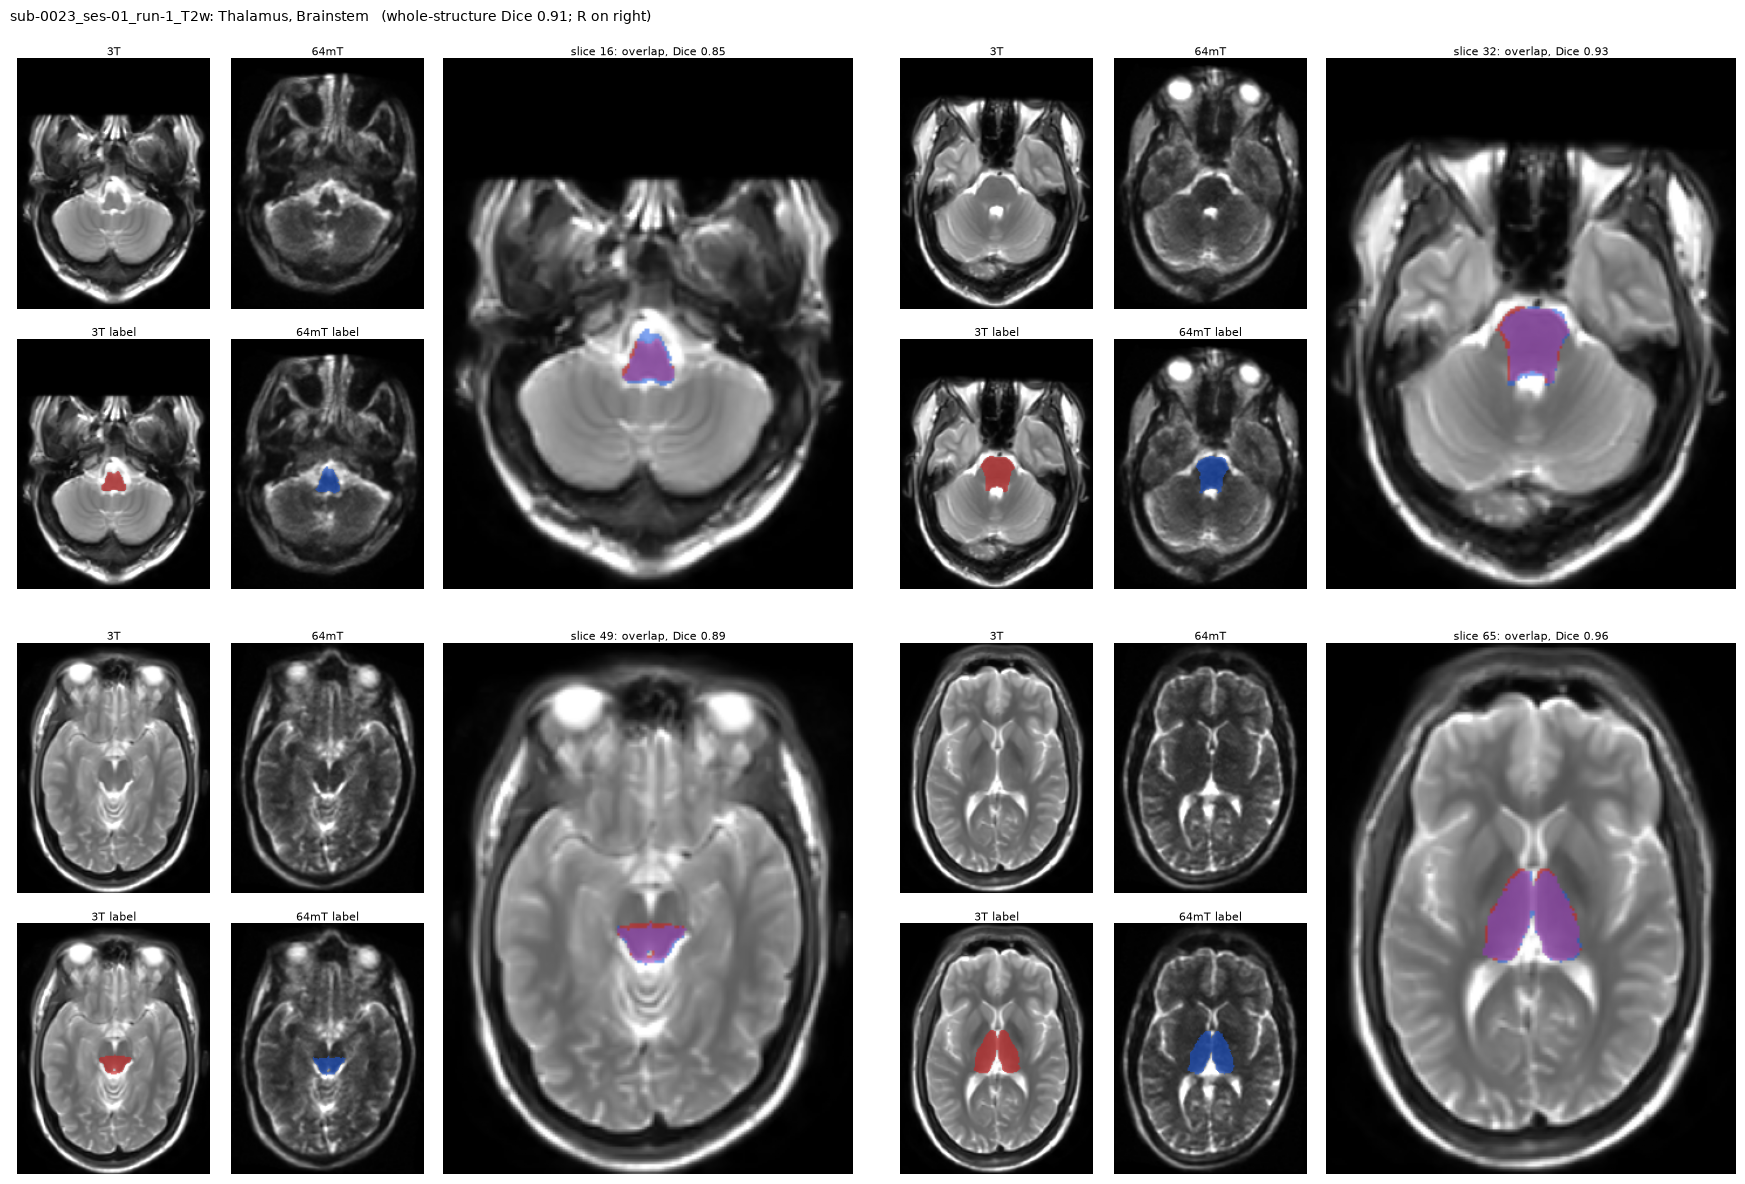

In [6]:
show_case(HIGH)

Dice is close to 0.9 and the volume bias is small. There is little room left for an enhancement
method to show improvement. The high score may also come partly from the tool's prior: these
structures have a fixed position and a predictable shape, so they can be placed well even when
the image carries little information.

### 2. Small structures

In [7]:
SMALL = ['3rd-Ventricle', '4th-Ventricle', 'Accumbens', 'Pallidum']
group_table(SMALL)

,Dice,Volume bias %,Dice,Volume bias %,Dice,Volume bias %
,T2w,T2w,T1w,T1w,FLAIR,FLAIR
3rd-Ventricle,0.79 (0.05),"-3 [-8, -0]",0.76 (0.07),"+17 [+11, +21]",0.58 (0.05),"-33 [-38, -5]"
4th-Ventricle,0.75 (0.09),"-3 [-8, +7]",0.71 (0.03),"+20 [+13, +23]",0.64 (0.10),"+35 [+25, +48]"
Accumbens,0.72 (0.06),"+1 [-3, +5]",0.75 (0.03),"-0 [-6, +4]",0.70 (0.13),"+2 [-3, +6]"
Pallidum,0.77 (0.06),"-7 [-13, -3]",0.78 (0.05),"-7 [-14, -1]",0.80 (0.04),"+18 [+5, +22]"


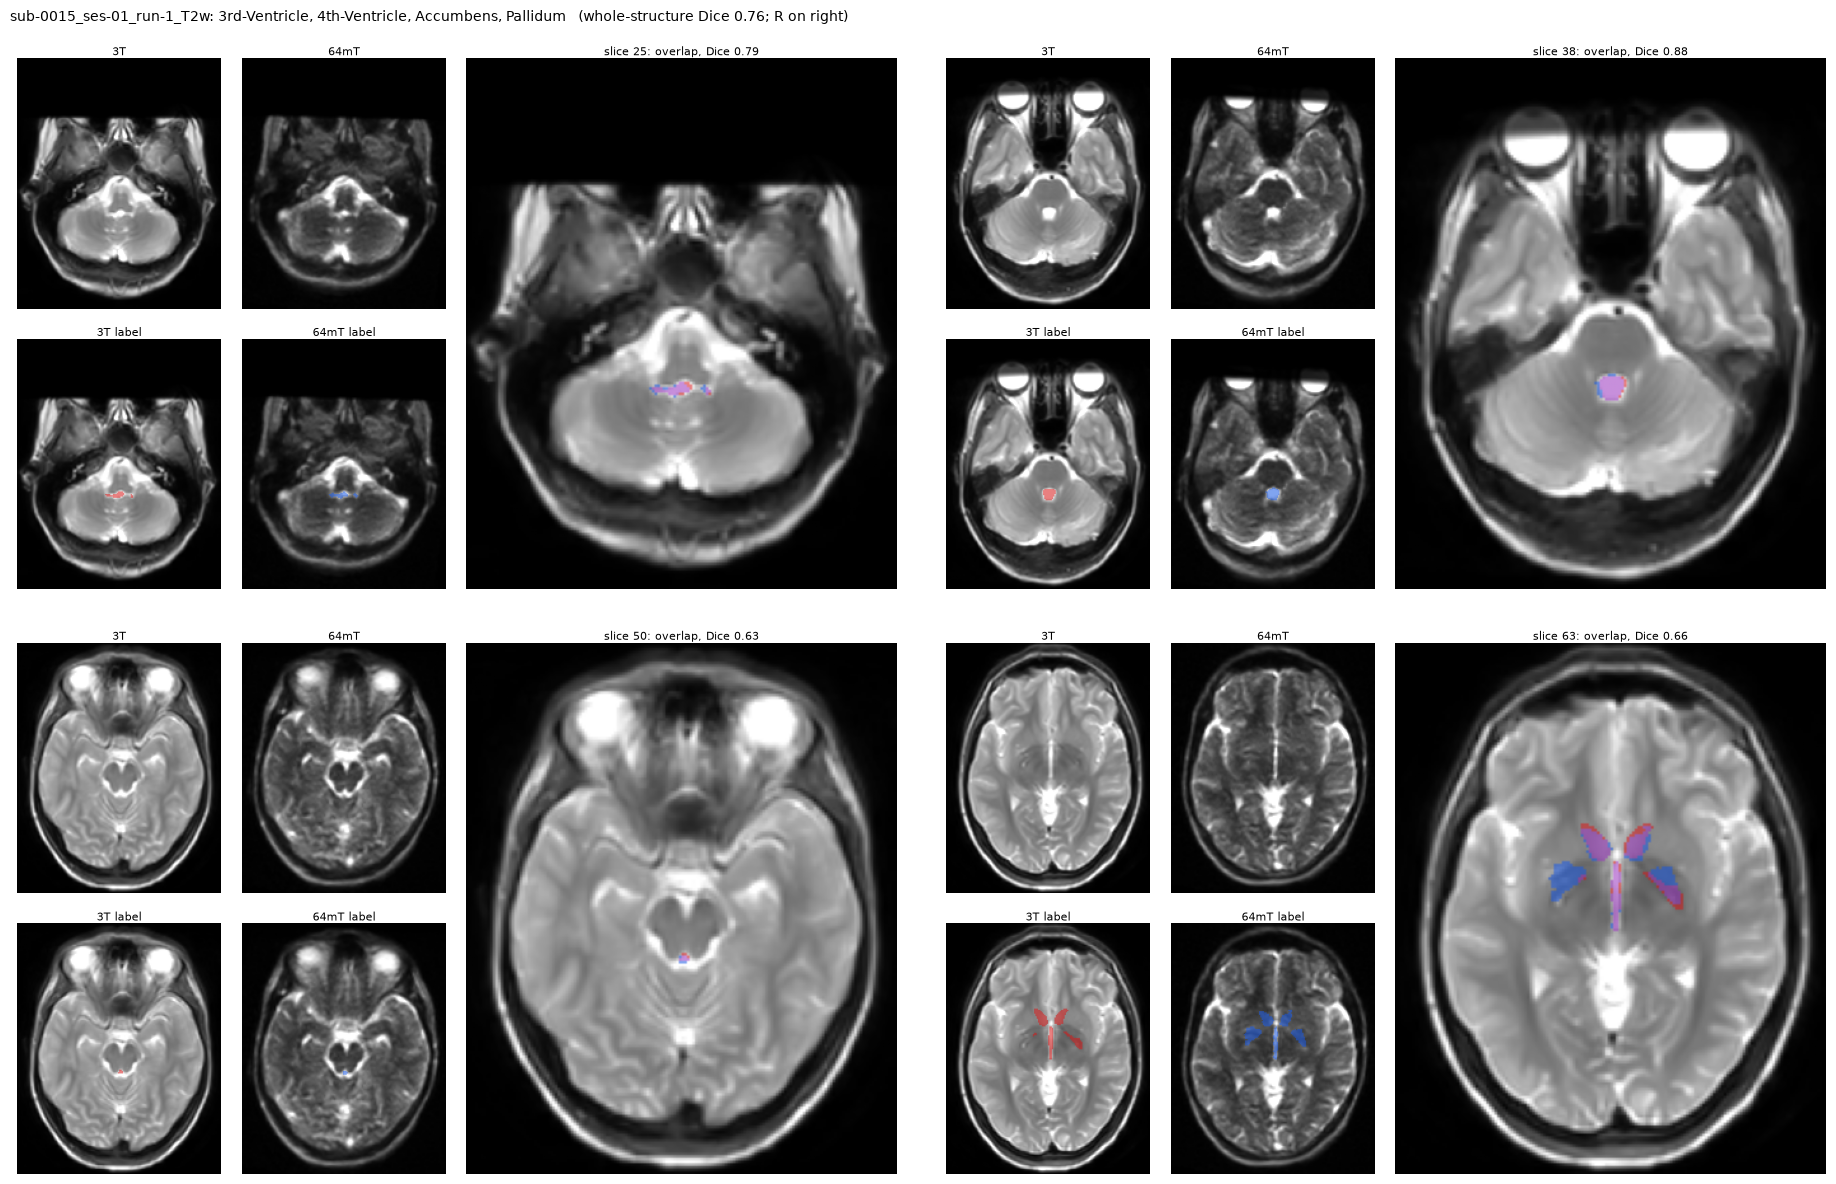

In [8]:
show_case(SMALL)

A few voxels make a large difference in both Dice and volume, so results jump between subjects
and sequences (widest on FLAIR). A real improvement would be hard to tell apart from this noise.

### 3. Large, low but stable: cortex and CSF

In [9]:
LARGE_LOW = ['Cortex', 'CSF']
group_table(LARGE_LOW)

,Dice,Volume bias %,Dice,Volume bias %,Dice,Volume bias %
,T2w,T2w,T1w,T1w,FLAIR,FLAIR
Cortex,0.74 (0.02),"+2 [+1, +2]",0.70 (0.02),"+6 [+4, +7]",0.71 (0.02),"+2 [+1, +5]"
CSF,0.60 (0.05),"+6 [+1, +7]",0.58 (0.05),"+12 [+8, +16]",0.57 (0.05),"+10 [+1, +14]"


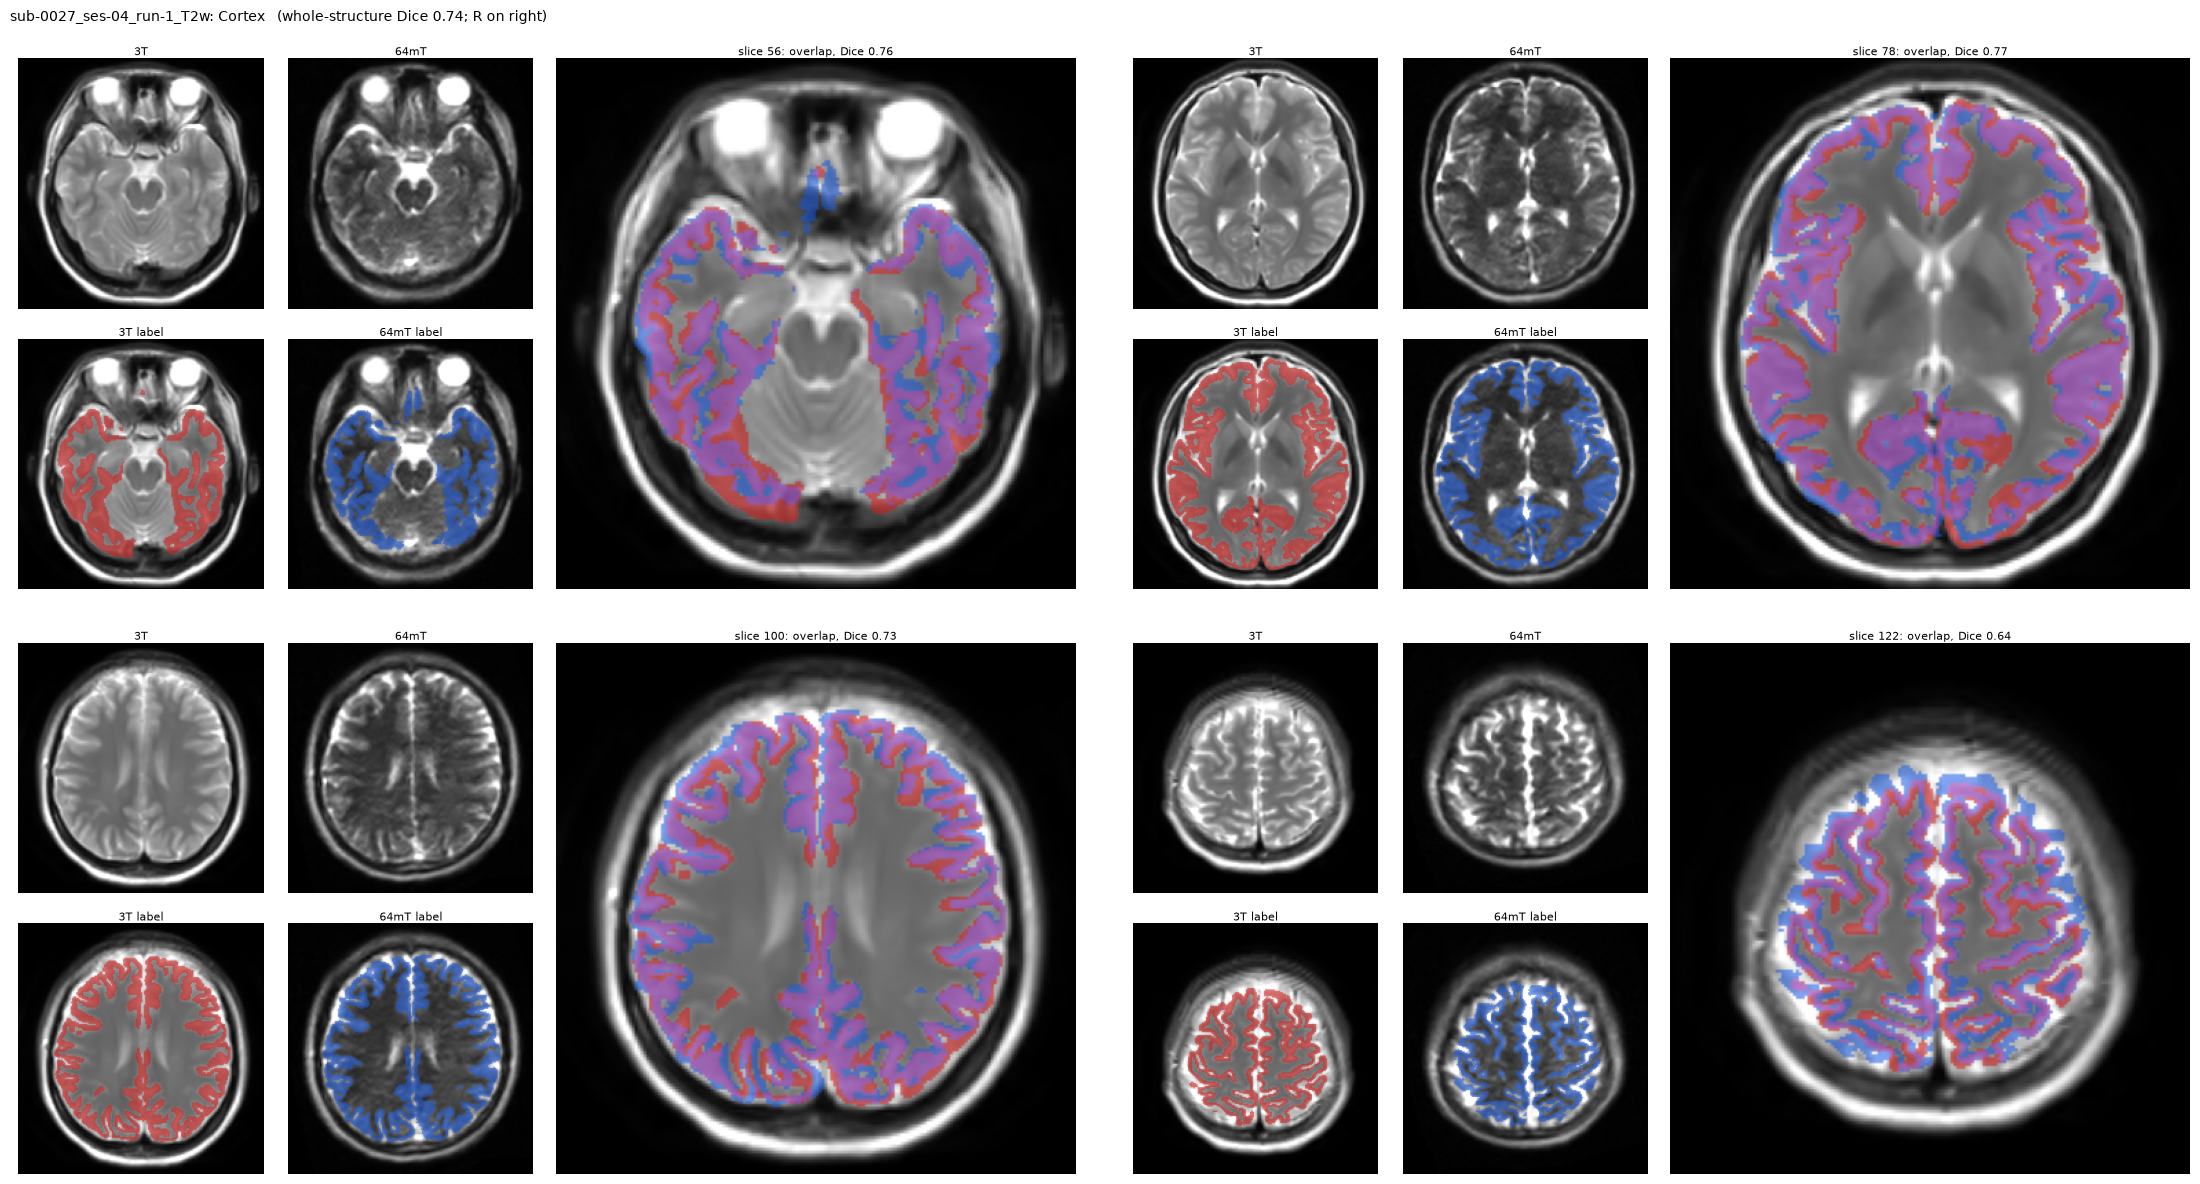

In [10]:
show_case(['Cortex'])

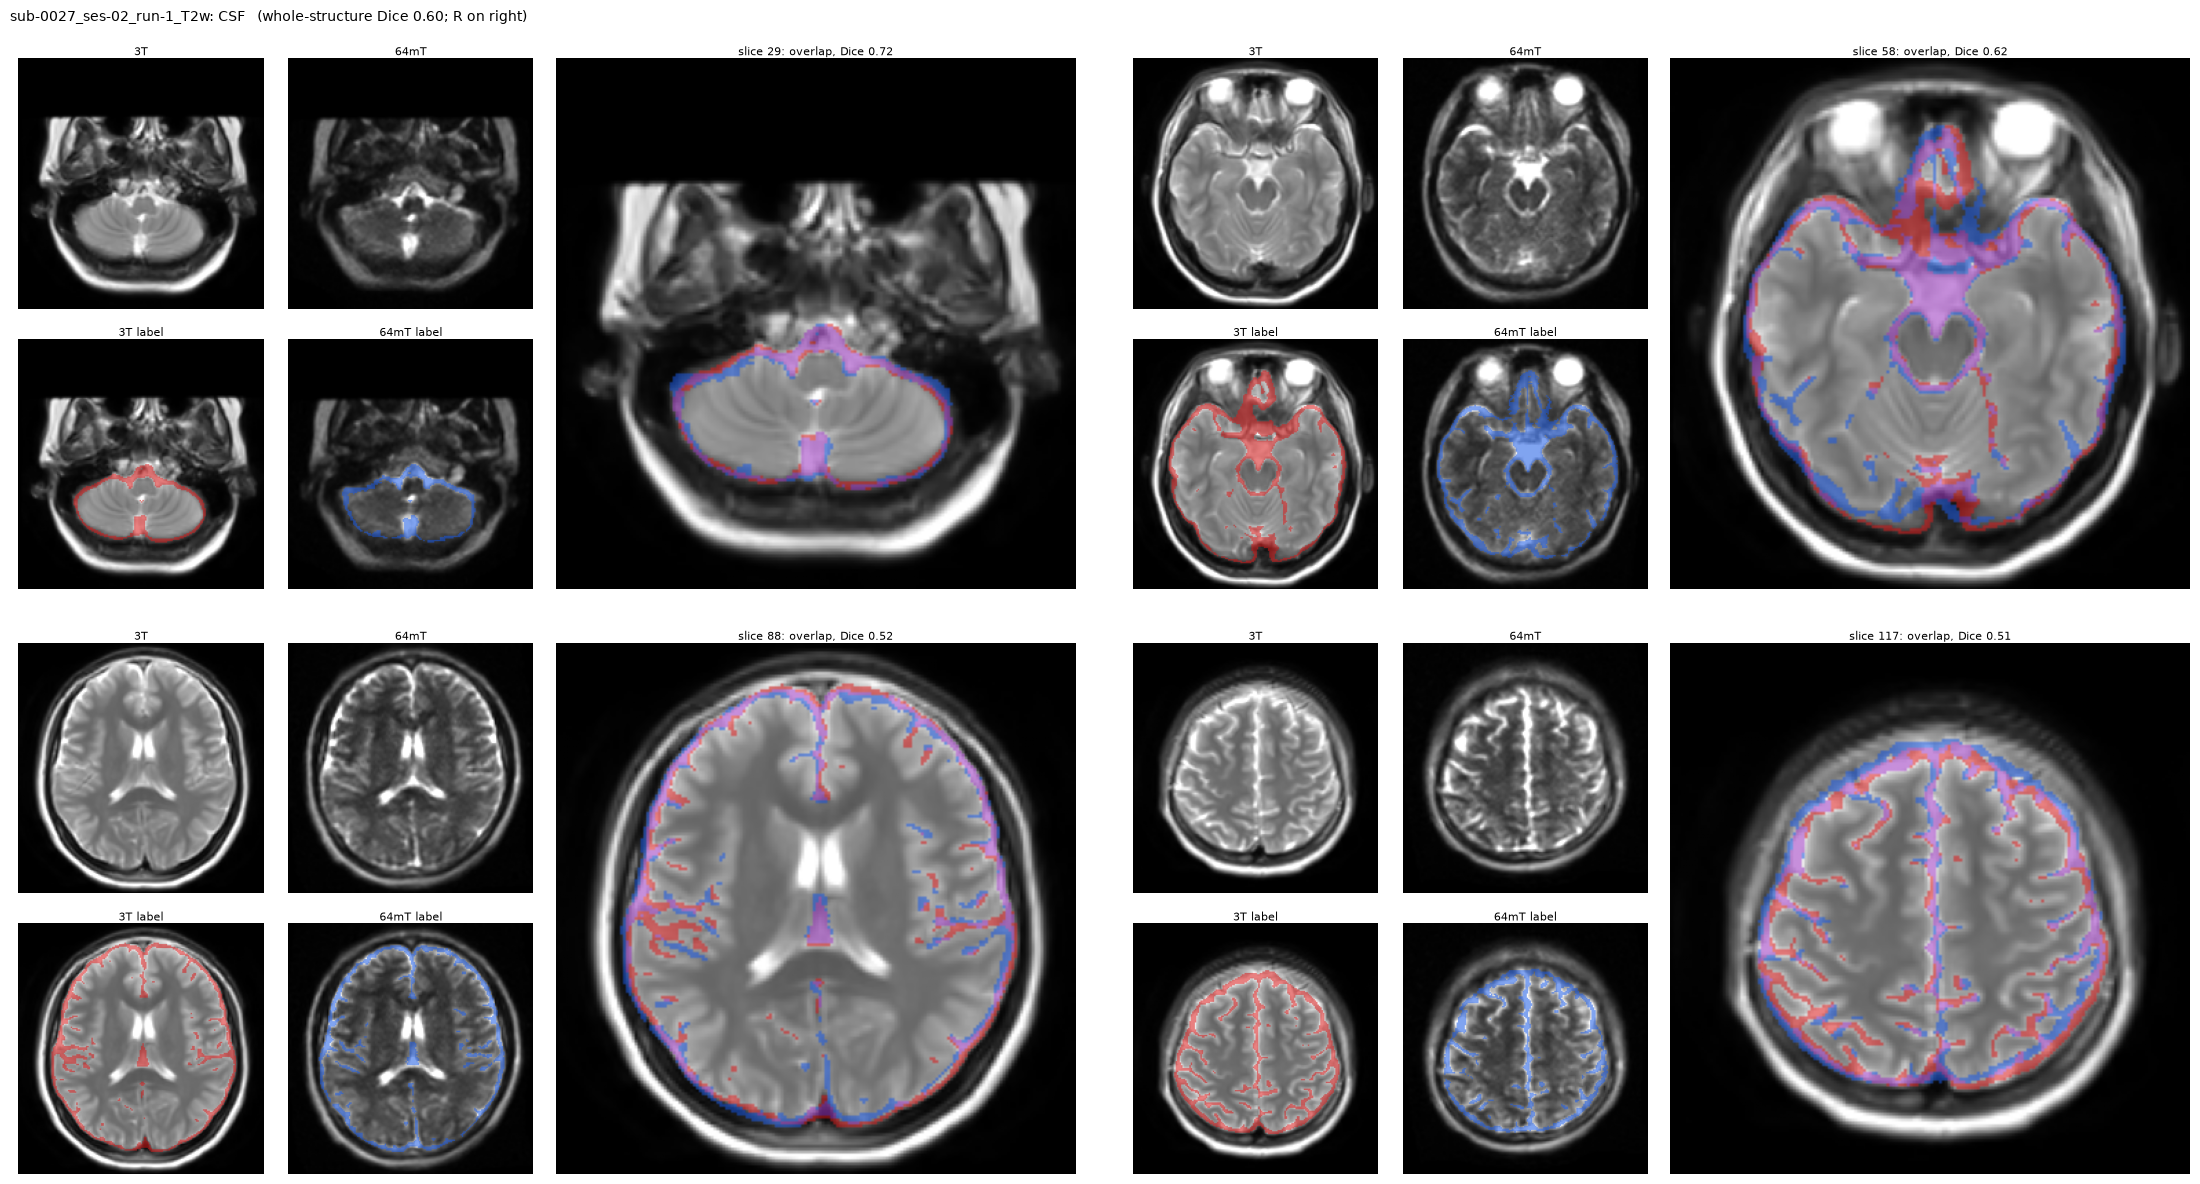

In [11]:
show_case(['CSF'])

Dice is low (cortex about 0.7, CSF about 0.6) but nearly the same in every subject, so there is
room to improve and an improvement would be visible. The disagreement sits along the thin,
folded boundary — where a loss of contrast at low field should show. The volume bias is small,
so volume alone would miss the gap.

## Conclusion

A structure suitable as a benchmark must:

1. **Have a low Dice** — room to improve, without being a segmentation failure;
2. **Be stable across subjects** — the gap is about the same for everyone, so an improvement is
   visible;
3. **Not be too small** — otherwise a few voxels dominate the result.

**Cortex and CSF meet all three.** They should be judged by **Dice, not volume**: an enhancement
model can generate plausible sulci in the wrong place while the volume still matches; Dice
penalises misplaced boundaries, volume does not. CSF on FLAIR should be used with care, as FLAIR
suppresses CSF signal by design.

**Next: a second dataset.** Chapter 08 repeats the analysis on a new dataset (12 subjects, a
different 3T scanner) to check whether cortex and CSF again show a gap to 3T that is stable
across subjects and leaves room for an enhancement method to improve.